# Class 21: Intro to Machine Learning

Plan for today:
- Creating confidence intervals
- Introduction to Machine Learning


In [ ]:
import YData

# YData.download.download_class_code(21)   # get class code    
# YData.download.download_class_code(21, True) # get the code with the answers 

# YData.download.download_homework(9)  # downloads the homework 


In [ ]:
import statistics
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
from urllib.request import urlopen

import matplotlib.pyplot as plt
%matplotlib inline


## 1. Using hypothesis tests to generate confidence intervals

There are several methods that can be used to calculate confidence intervals, including using a computational method called the "bootstrap" and using "parametric methods" that involve using probability distributions. If you take a traditional introductory statistics class you will learn some of these methods.

Below we use a less conventional method to calculate confidence intervals by looking at all parameter values that a hypothesis test fails to reject (at the p-value < 0.05 level). As you will see, the method gives similar results to other methods, although it requires a bit more computation time.

As an example, let's create a confidence interval for the population proportion of movies $\pi$ that pass the Bechdel test. As is the case for all confidence intervals, this confidence interval gives a range of plausible values that likely contains the true population proportion $\pi$.


In [ ]:
# To start, let's use a function that generates a statistic p-hat that is consistent with a particular population parameter value pi

def generate_proportion(n, prob_heads):
    
    random_sample = np.random.rand(n) <= prob_heads
    return np.mean(random_sample)

generate_proportion(1794, .5)



np.float64(0.49944258639910816)

In [ ]:
# The function below calculates a p-value for the Bechdel data based on a particular pi value that is specified in a null hypothesis.
# (i.e., it is a function that encapsulates the hypothesis test you ran in class 17).


def get_Bechdel_pvalue(null_hypothesis_pi, plot_null_dist = False):
    
    
    # The observed p-hat value
    prop_passed = 803/1794
    
    
    # Generate the null distribution 
    null_dist = []
    
    for i in range(10000):    
        null_dist.append(generate_proportion(1794, null_hypothesis_pi))
    
    
    # Calculate a "two-tailed" p-value which is the proportion of statistcs more extreme than the observed statistic

    statistic_deviation = np.abs(null_hypothesis_pi - prop_passed)  # distance between p-hat and pi_0
    
    pval_left = np.mean(np.array(null_dist) <= null_hypothesis_pi - statistic_deviation)
    pval_right = np.mean(np.array(null_dist) >= null_hypothesis_pi + statistic_deviation)    
    
    p_value = pval_left + pval_right


    
    # plot the null distribution and lines indicating values more extreme than the observed statistic 
    if plot_null_dist:
        
        plt.hist(null_dist, edgecolor = "black", bins = 30);
        plt.axvline(null_hypothesis_pi - statistic_deviation, color = "red");
        plt.axvline(null_hypothesis_pi + statistic_deviation, color = "red");
        plt.axvline(prop_passed, color = "green");
        plt.axvline(null_hypothesis_pi, color = "yellow");

        
        plt.title("Pi-null is: " + str(null_hypothesis_pi) + "      "  +
                  "p-value is: " + str(round(p_value, 5)))
      
    # return the p-value
    return p_value
    


np.float64(0.8473999999999999)

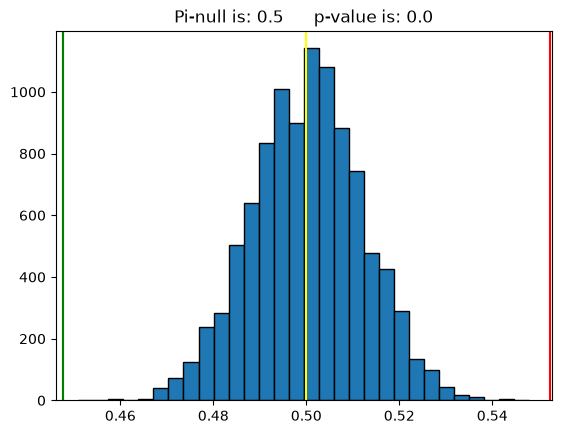

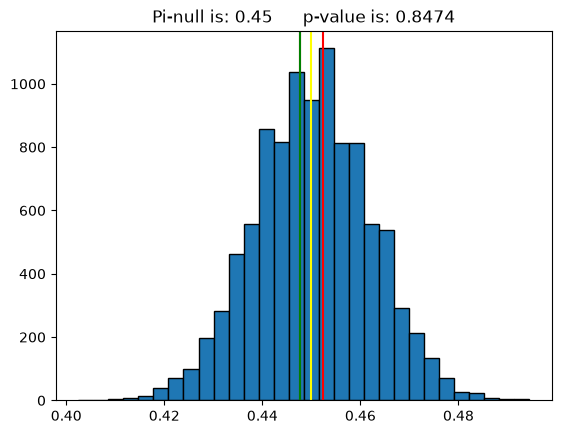

In [ ]:
# test the function with the value H0: pi = .5  (as we did in class 17)
get_Bechdel_pvalue(.5, True)


# test the function with the value H0: pi = .45
plt.figure()
get_Bechdel_pvalue(.45, True)

In [ ]:
# create a range of H0: pi = x  values

possible_null_pis = np.round(np.arange(.4, .5, .005), 5)

possible_null_pis    


array([0.4  , 0.405, 0.41 , 0.415, 0.42 , 0.425, 0.43 , 0.435, 0.44 ,
       0.445, 0.45 , 0.455, 0.46 , 0.465, 0.47 , 0.475, 0.48 , 0.485,
       0.49 , 0.495])

In [ ]:
%%time


# get the p-value for a range of H0: pi = x  values


pvalues = []

for null_pi in possible_null_pis:
    
    curr_pvalue = get_Bechdel_pvalue(null_pi)
    
    pvalues.append(curr_pvalue)



CPU times: user 3.73 s, sys: 125 ms, total: 3.85 s
Wall time: 14.7 s


In [ ]:
# view the p-values 
# convention calls a p-value < 0.05 "statistically significant", indicating a pi incompatible with the null hypothesis
# our confidence interval is all pi values that are not statistically significant (i.e., pi values that are consistent with particular H0)

pvalue_df = pd.DataFrame({"pi": possible_null_pis, 
                          "p-values": pvalues,
                          "non-significant": np.array(pvalues) > .05})

pvalue_df


,pi,p-values,non-significant
0,0.400,0.0001,False
1,0.405,0.0001,False
2,0.410,0.0007,False
3,0.415,0.0047,False
4,0.420,0.0184,False
5,0.425,0.0513,True
6,0.430,0.1343,True
7,0.435,0.2908,True
8,0.440,0.5185,True
9,0.445,0.8310,True


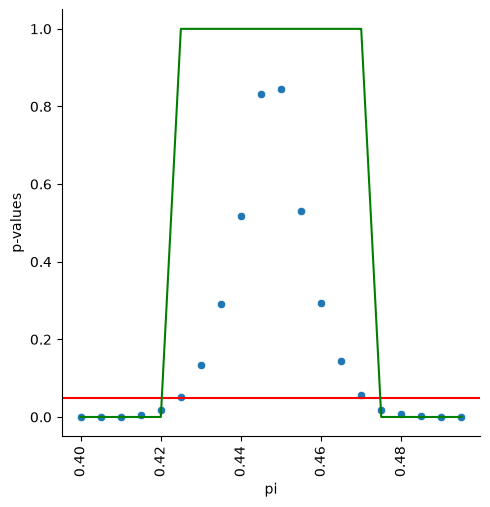

In [ ]:
# plot p-values as a function of H0 pi's

sns.relplot(pvalue_df, x = 'pi', y = 'p-values');
plt.xticks(rotation=90);
plt.axhline(.05, color = "red");

plt.plot(pvalue_df['pi'], pvalue_df['non-significant'], color = "green");


In [ ]:
# Get all plausible Pi values
fail_to_reject_pis = possible_null_pis[np.array(pvalues) >= .05]

fail_to_reject_pis


array([0.425, 0.43 , 0.435, 0.44 , 0.445, 0.45 , 0.455, 0.46 , 0.465,
       0.47 ])

In [ ]:
# get the CI as the max and min plausible pi values 

(min(fail_to_reject_pis), max(fail_to_reject_pis))

(np.float64(0.425), np.float64(0.47))

In [ ]:
# using the statsmodels package to compute a confidence interval for a proportion

import statsmodels.api as sm

ci_low, ci_upp = sm.stats.proportion_confint(803, 1794, alpha=0.05, method='normal')
(round(ci_low, 3), round(ci_upp, 3))


(0.425, 0.471)

## 2. Intro to Machine Learning:  Features (X) and labels (y)

In supervised machine learning, we use a computer algorithm called a "pattern classifier" to learn relationships between a set of features X, and a label y. When the classifier is given new examples X, it can then make new predictions y. 


In [ ]:
penguins = sns.load_dataset("penguins")

penguins = penguins.dropna()

penguins = penguins.sample(frac = 1)

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
292,Gentoo,Biscoe,48.2,15.6,221.0,5100.0,Male
288,Gentoo,Biscoe,43.5,14.2,220.0,4700.0,Female
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,Male
24,Adelie,Biscoe,38.8,17.2,180.0,3800.0,Male
57,Adelie,Biscoe,40.6,18.8,193.0,3800.0,Male


In [ ]:
# Let's explore how many different members there are of each species in our data set? 

species_counts = penguins.groupby("species").agg(count = ('island', 'count'))

species_counts


,count
species,
Adelie,146
Chinstrap,68
Gentoo,119


#### Questions: 

1. If we had to guess the species of the penguin without knowing any of the penguin's features, species of penguin should we guess? 
A: Always guess Adelie


2. If we were to following the optimal guessing strategy, what percent of our guess would be correct (i.e., what would our classification accuracy be)? 


In [ ]:
species_counts['count']/sum(species_counts['count'])

species
Adelie       0.438438
Chinstrap    0.204204
Gentoo       0.357357
Name: count, dtype: float64

To begin the classification process, let's store the features (X) and the labels (y) in separate names called `X_penguin_features` and `y_penguin_labels` respectively. 

In [ ]:
# get the features and the labels

X_penguin_features = penguins[['bill_length_mm', 
                               'bill_depth_mm',
                               'flipper_length_mm', 
                               'body_mass_g']]

y_penguin_labels = penguins['species']


## 3. k-Nearest Neighbors classifier


To explore classification, let's use a k-Nearest Neighbors classifier to predict the species of a penguin based on particular features the penguin has such as the penguin's bill length and body mass. 

Let's construct a K-Nearest Neighbor classifier (KNN) using 5 neighbors for predictions (i.e., k = 5 so we are using a 5-Nearest Neighbor classifier). 

We can do this using the `KNeighborsClassifier(n_neighbors = )` function.  


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Construct a classifier a 5 nearest neighbor classifier
knn = KNeighborsClassifier(n_neighbors = 5) 

Let's now train the classifier (the KNN classifier just stores the data during training)


In [ ]:
# “train” the classifier (which for a KNN classifier just involves memorizing the training data)

knn.fit(X_penguin_features, y_penguin_labels) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Adelie','Chinstrap','Gentoo']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Let's now use the classifier to make predictions

In [ ]:
# make predictions
penguin_preditions = knn.predict(X_penguin_features)

penguin_preditions[0:10]

array(['Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Chinstrap'], dtype=object)

Let's get the prediction (classificaton accuracy) which is the proportion of predictions that are correct

In [ ]:
# get the classification accuracy
np.mean(penguin_preditions == y_penguin_labels)

np.float64(0.8378378378378378)

Let's repeat our analysis with k = 1 to see what happens...

In [ ]:
# What happens if k = 1?

# construct a classifier
knn = KNeighborsClassifier(n_neighbors = 1) 

# “train” the classifier (which for a KNN classifier just involves memorizing the training data)
knn.fit(X_penguin_features, y_penguin_labels) 

# make predictions
penguin_preditions = knn.predict(X_penguin_features)

# get classification accuracy
np.mean(penguin_preditions == y_penguin_labels)

np.float64(1.0)

Do we believe we have a perfect classifier???


## 4. Cross-validation

To avoid over-fitting, we need to split our data into a training and test set. 

The classifier "learns" the relationship between features (X) and labels (y) on the **training set**.

The classifier makes predictions on the features (X) of the **test set**. 

We compare the classifier's predictions on the test features (X) to the actual labels y, to get a more accuracy assessment of the **classification accuracy**.


Let's try this now...



In [ ]:
# manually create a training with 250 examples, and a test set that has the rest of the data

X_train_manual = X_penguin_features.iloc[0:250, :]
y_train_manual = y_penguin_labels.iloc[0:250]

X_test_manual = X_penguin_features.iloc[250:, :]
y_test_manual = y_penguin_labels.iloc[250:]


print(X_train_manual.shape)
print(X_test_manual.shape)


(250, 4)
(83, 4)


In [ ]:
from sklearn.model_selection import train_test_split

# split data into a training and test set

X_train, X_test, y_train, y_test = train_test_split(X_penguin_features,  
                                                    y_penguin_labels, 
                                                    random_state = 0)

print(X_train.shape)
print(X_test.shape)

X_train.head(3)


(249, 4)
(84, 4)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
95,40.8,18.9,208.0,4300.0
234,45.8,14.6,210.0,4200.0
259,48.7,15.7,208.0,5350.0


We now have two training and test sets made from the same data: the one we made by hand (`X_train_manual`, `X_test_manual`, …) and the one from `train_test_split()` (`X_train`, `X_test`, …). `train_test_split()` puts 25% of the rows in the test set by default, and `random_state = 0` makes it pick the same rows if we run the cell again. Both splits are random, because we shuffled the rows when we loaded the data. Below we use the split we made by hand; we use the `train_test_split()` one in section 6, when we build our own classifier.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


# construct a classifier
knn = KNeighborsClassifier(n_neighbors = 1) 

# “train” the classifier (which for a KNN classifier just involves memorizing the training data)
knn.fit(X_train_manual, y_train_manual) 



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Adelie','Chinstrap','Gentoo']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
# get the predictions

penguin_preditions = knn.predict(X_test_manual)

penguin_preditions


array(['Gentoo', 'Gentoo', 'Gentoo', 'Gentoo', 'Chinstrap', 'Gentoo',
       'Chinstrap', 'Adelie', 'Adelie', 'Gentoo', 'Gentoo', 'Gentoo',
       'Adelie', 'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Chinstrap',
       'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Chinstrap', 'Adelie',
       'Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Gentoo', 'Adelie',
       'Gentoo', 'Adelie', 'Gentoo', 'Gentoo', 'Chinstrap', 'Gentoo',
       'Chinstrap', 'Chinstrap', 'Adelie', 'Chinstrap', 'Chinstrap',
       'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Gentoo', 'Adelie',
       'Adelie', 'Chinstrap', 'Adelie', 'Gentoo', 'Gentoo', 'Gentoo',
       'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Chinstrap', 'Chinstrap',
       'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Gentoo',
       'Adelie', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie', 'Gentoo',
       'Gentoo', 'Gentoo', 'Gentoo', 'Gentoo', 'Chinstrap', 'Gentoo',
       'Adelie', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie'],
      dtype=object)

In [ ]:
# Get the prediction accuracy 

np.mean(penguin_preditions == y_test_manual)


np.float64(0.8192771084337349)

In [ ]:
# Test the classifier on the test set using the .score() method

knn.score(X_test_manual, y_test_manual) # prediction accuracy on the test set

0.8192771084337349

In [ ]:
# What happens if we test the classifier on the training set? 

knn.score(X_train_manual, y_train_manual) # prediction accuracy on the training set


1.0

### K-fold cross-validation

In k-fold cross-validation we split our data into k-parts (note, the k here has no relation to the k in k-Nearest Neighbor - it is just that k is a frequent letter to use in math to denote integer values).  

To run a k-fold cross-validation analysis, we train the classifier on k-1 parts of the data and test it on the remaining part. We repeat this process k times to get k classification accuracies. We then take the average of these results as our estimate of our overall classification accuracy. 

We can use the scikit-learn `cross_val_score()` to easily do this...


In [ ]:
from sklearn.model_selection import cross_val_score

knn = KNeighborsClassifier(n_neighbors = 1) # construct knn classifier

# do 5-fold cross-validation
scores = cross_val_score(knn, X_penguin_features,  y_penguin_labels, cv = 5)

print(scores)

print(scores.mean())


[0.89552239 0.79104478 0.89552239 0.81818182 0.83333333]
0.8467209407507916


## 5. Other classifiers

Many other types of classifiers that have been created. Scikit-learn makes it very easy to try out a range of classifiers. 

Let's explore the Support Vector Machine, and Random Forest Classifier on our penguin data...

In [ ]:
# Suppress ConvergenceWarning if we need it.
#import warnings
#from sklearn.exceptions import ConvergenceWarning
#warnings.filterwarnings("ignore", category=ConvergenceWarning)
#warnings.filterwarnings("ignore", category=FutureWarning)


# Try a support vector machine (SVM)

from sklearn.svm import LinearSVC

svm = LinearSVC()   # max_iter=10000

scores = cross_val_score(svm, X_penguin_features,  y_penguin_labels, cv = 5)

print(scores.mean())


0.9849389416553596


In [ ]:
# Try a random forest

from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier()

scores = cross_val_score(random_forest, X_penguin_features,  y_penguin_labels, cv = 5)

print(scores.mean())


0.9759837177747626


## 6. Building the KNN classifier

So far we have used the KNN classifier (and a few other classifiers). Let's now see if we can write code that will implement the KNN classifier.

We will do this by writing a several helper functions that build on each other. These functions are: 

1. `euclid_dist(x1, x2)`: finds the Euclidean distance between two points `x1` and `x2`

2. `get_labels_and_distances(test_point, X_train_features, y_train_labels)`: This function finds the distance between a test point and all the training points. It returns a DataFrame with the distance from all training points and the training labels for each point.

3. `classify_point(test_point, k, X_train_features, y_train_labels)`: Classifies which class a test point belongs to

4. `classify_all_test_data(X_test_data, k, X_train_features, y_train_labels)`: Classifiers which class all test points below to.


Let's start by writing a function that can get the Euclidean distance between two points `x` and `z`: 

$$dist(x, z) = \sqrt{\Sigma_{i = 1}^d (x_i - z_i)^2)}$$


In [ ]:
def euclid_dist(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))


# test our function 
my_vec1 = np.array([1, 2, 3, 4])
my_vec2 = np.array([2, 3, 4, 5])

euclid_dist(my_vec1, my_vec2)


np.float64(2.0)

In [ ]:
# Let's now write a function that returns the labels and distances 
# between a test point and all the training points


def get_labels_and_distances(test_point, X_train_features, y_train_labels):
    
    the_distances = []
    
    # get the distance between the test point and all training points
    for i in range(X_train_features.shape[0]):
        the_distances.append(euclid_dist(test_point, X_train_features.iloc[i]))

    
    # Create a DataFrame with the training labels and distances 
    labels_and_distances = pd.DataFrame({'label': y_train_labels, 'distance':the_distances})
    return labels_and_distances



# test our code 

test_data_point = X_test.iloc[0]
test_label = y_test.iloc[0]

labels_and_distances = get_labels_and_distances(test_data_point, X_train, y_train)

labels_and_distances.head(5)


,label,distance
95,Adelie,300.113279
234,Gentoo,400.005062
259,Gentoo,750.003127
172,Chinstrap,1000.409726
262,Gentoo,300.010150


In [ ]:
# get the k closest neighbors

k = 5

sorted_labels_dist = labels_and_distances.sort_values("distance")

sorted_labels_dist = sorted_labels_dist.iloc[0:k]

sorted_labels_dist

,label,distance
306,Gentoo,9.891916
45,Adelie,21.084829
300,Gentoo,25.231924
318,Gentoo,25.726446
232,Gentoo,50.291649


In [ ]:
# get the majority label

count_table = sorted_labels_dist.groupby("label").count().reset_index()

sorted_count_table = count_table.sort_values("distance", ascending = False)

sorted_count_table.iloc[0]["label"]

'Gentoo'

In [ ]:
# write a function to do the classification on a test point 
# by putting together all the pieces

def classify_point(test_point, k, X_train_features, y_train_labels):
    
    labels_and_distances =  get_labels_and_distances(test_point, 
                                                     X_train_features, 
                                                     y_train_labels)

    sorted_labels_dist = labels_and_distances.sort_values("distance")
    sorted_labels_dist = sorted_labels_dist.iloc[0:k]
    
    
    count_table = sorted_labels_dist.groupby("label").count().reset_index()
    sorted_count_table = count_table.sort_values("distance", ascending = False)
    majority_class = sorted_count_table.iloc[0]["label"]
    
    return majority_class


# test our classifier on one test point

prediction = classify_point(test_data_point, 5, X_train, y_train)

print(prediction)

print(test_label)


Gentoo
Gentoo


In [ ]:
# classify a full test set

def classify_all_test_data(X_test_data, k, X_train_features, y_train_labels):
    
    predictions = []
    
    for i in range(X_test_data.shape[0]):
        
        curr_test_point = X_test_data.iloc[i]
        
        curr_prediction = classify_point(curr_test_point, 
                                         k, 
                                         X_train_features, 
                                         y_train_labels)
        
        predictions.append(curr_prediction)

    return np.array(predictions)
    


# test the classifier on the whole test set    

all_predictions = classify_all_test_data(X_test, 5, X_train, y_train)

all_predictions


array(['Gentoo', 'Adelie', 'Gentoo', 'Gentoo', 'Gentoo', 'Adelie',
       'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Adelie', 'Gentoo',
       'Adelie', 'Chinstrap', 'Gentoo', 'Adelie', 'Adelie', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Gentoo',
       'Adelie', 'Adelie', 'Gentoo', 'Adelie', 'Gentoo', 'Adelie',
       'Chinstrap', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap', 'Gentoo',
       'Adelie', 'Gentoo', 'Gentoo', 'Chinstrap', 'Gentoo', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Chinstrap', 'Gentoo', 'Adelie', 'Adelie', 'Gentoo', 'Adelie',
       'Adelie', 'Gentoo', 'Adelie', 'Adelie', 'Adelie', 'Adelie',
       'Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Chinstrap', 'Adelie',
       'Gentoo', 'Gentoo', 'Gentoo', 'Adelie', 'Gentoo', 'Adelie',
       'Gentoo', 'Adelie', 'Gentoo', 'Adelie', 'Gentoo', 'Adelie',
       'Adelie', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie', 'Adelie'],
      dtype='<U9')

In [ ]:
# get the classification accuracy

np.mean(all_predictions == y_test)



np.float64(0.75)